# AP 155 Lab Exercise
---
## Exercise 11: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Rivera, Kyle Florian
- _Student No._: 2024-16197
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![Fourier Transform of square waves with varying frequency](square_freqs.png)
Figure 1: Fourier Transform of square waves with varying frequency

![Fourier Transform of square waves with varying frequency](recover.png)
Figure 2: Recovery of a noisy signal using Inverse Fourier Transform

![Fourier Transform of square waves with varying frequency](recover_lowersample.png)
Figure 3: Recovery of a noisy signal using a lower sampling rate

![Fourier Transform of square waves with varying frequency](aliasing.png)
Figure 4: Fourier Transform of aliased and unaliased waveforms

### Report discussion

1. How does changing the shape of the input signal affects it transform?
   
- To easily visualize the changes, we varied the frequency of a square wave. The magnitude of the Fourier Transform peaks at odd harmonics and decays as we get to a higher and higher frequency. Increasing the frequency of the square wave inversely changes the rate of decay of the magnitude, i.e. as frequency increases, the rate of decay decreases. Meanwhile, the phase of the FT climbs in a straight line, while decreasing the number of points in the said line. However, this is because there are less points (frequencies) as we are only looking from $[0,10]$

2. What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why?

- As we decrease N, the peaks get wider and the resolution decreases. Despite this, signal recovery is still possible, although finer details may be lost as the peaks becomes harder to pick out due to the noise. Because of this, there is a limit of N to which a signal can be recovered as once N is small enough, the noise is as big as the peaks, yielding nothing but noise.

3. Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave.

- The frequency of the signal is 7.5 Hz, giving a Nyquist frequency of 15 Hz. For the aliased wave, a sampling frequency of 12.5 Hz was used while 100 Hz sampling frequency was used for unaliased wave. For the non-aliased wave, it can be seen that the peaks of the Fourier Transform correctly match and the samples traces the original waveform. Meanwhile, for the aliased wave, the Fourier Transform only covers frequencies within $\pm 6.25$ Hz. As such, the waveform traced by the aliased wave looks jagged and can be told apart from the original waveform, unlike the unaliased wave which overlays the original waveform perfectly well.

### Other comments
- No comment.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy import signal

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

We can generate three sample waveforms: square, sawtooth, and gaussian.

In [2]:
interval = 0.05
t = np.arange(0, 10, interval)
N = len(t)

signals = ['square', 'sawtooth', 'gausspulse']
signal_data = {}

def generate_signals(freq):
    signal_data['square'] = signal.square(freq*t*2*np.pi)
    signal_data['sawtooth'] = signal.sawtooth(freq*t*2*np.pi)
    signal_data['gausspulse'] = signal.gausspulse(t-5, fc=freq*4) # centered at x = 5
    return

generate_signals(0.5)

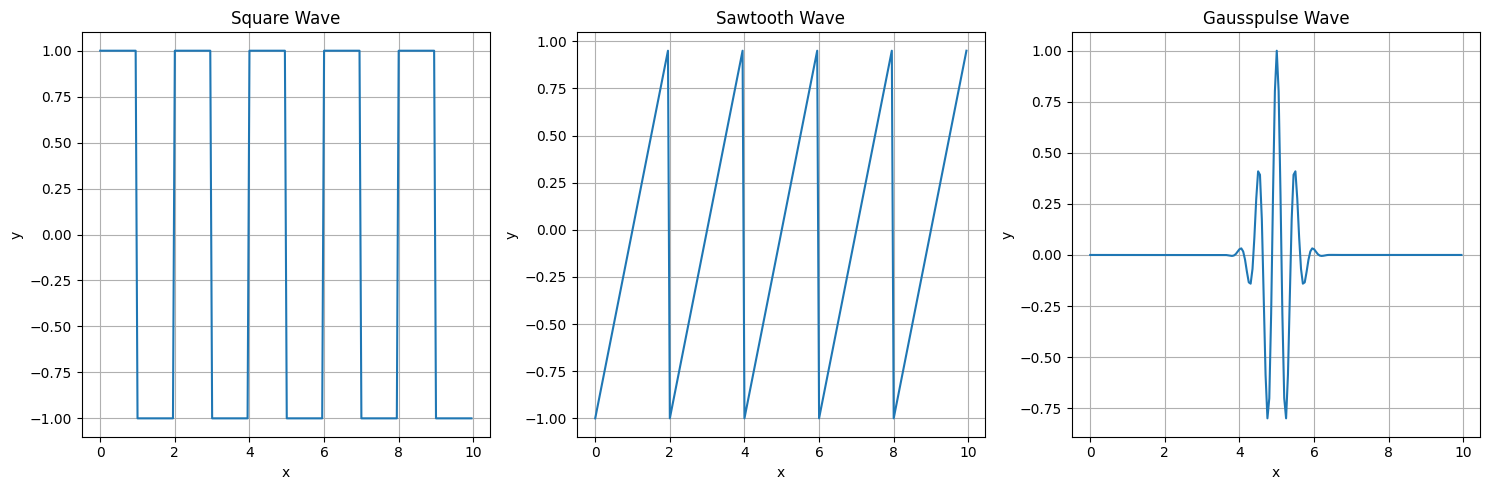

In [3]:
fig, axs = plt.subplots(1,3, figsize=(15,5))

for signal_type, ax in zip(signals, axs):  
    ax.plot(t, signal_data[signal_type])
    ax.set_title(f'{signal_type.title()} Wave')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.grid(True)

plt.tight_layout()
plt.show()
# print(signal_data['square'])

We can now plot the magnitude of the Fourier Transform

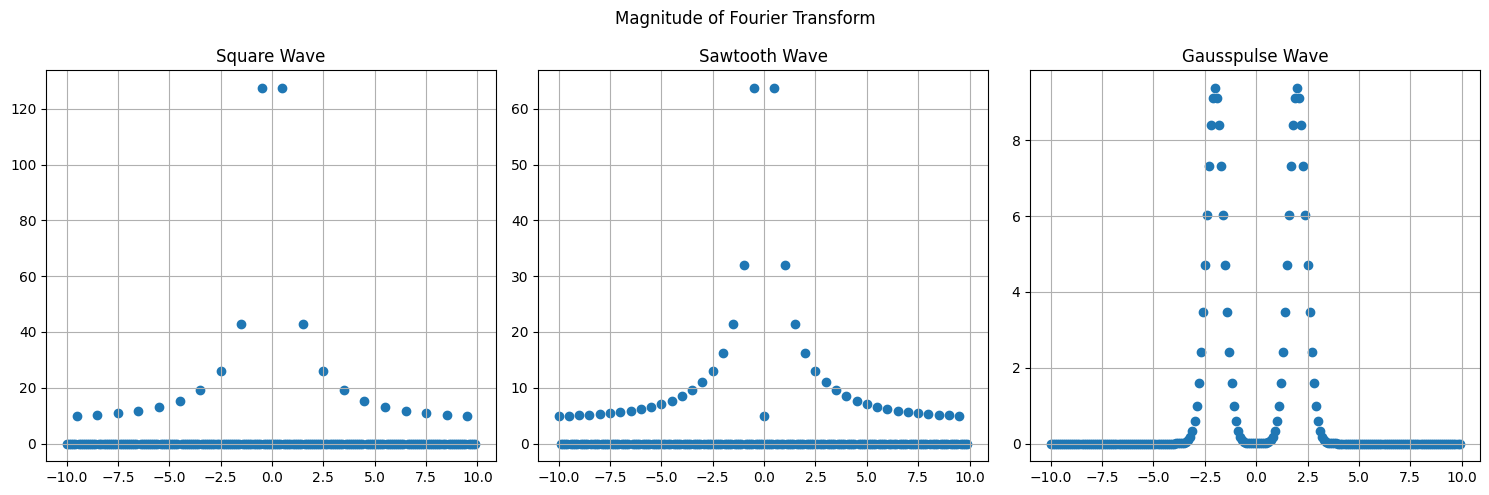

In [4]:
fig, axs = plt.subplots(1,3, figsize=(15,5))
freq_signal = np.fft.fftfreq(N, interval)

for data, ax in zip(signals, axs):
    signal_ft = np.fft.fft(signal_data[data])
    # find fft
    mag_signal = np.abs(signal_ft)

    # shift freq and magnitude 
    freq_shifted = np.fft.fftshift(freq_signal)
    mag_shifted = np.fft.fftshift(mag_signal)
    
    ax.scatter(freq_shifted, mag_shifted)
    ax.grid(True)
    ax.set_title(f'{data.title()} Wave')

plt.suptitle(f'Magnitude of Fourier Transform')
plt.tight_layout()
plt.show()

And the phase of it as well

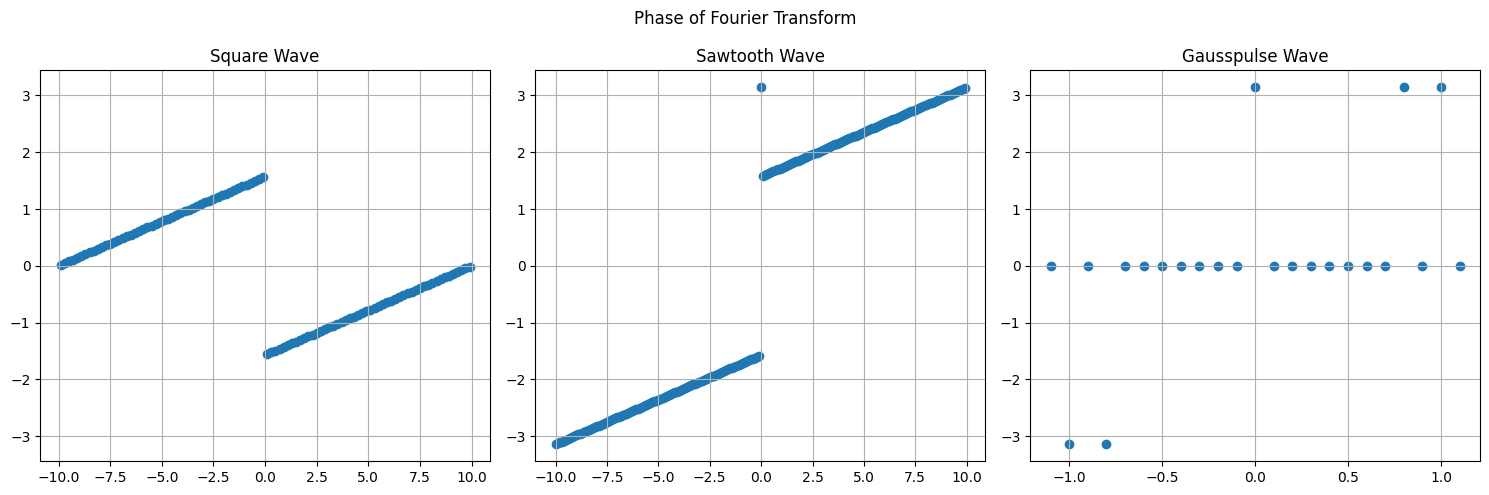

In [5]:
fig, axs = plt.subplots(1,3, figsize=(15,5))
signal_data={}
generate_signals(0.1)
freq_shifted = np.fft.fftshift(np.fft.fftfreq(N, interval))

for data, ax in zip(signals, axs):
    sig = signal_data[data]
    if data == 'gausspulse':
        sig = np.fft.ifftshift(sig)  # put the pulse center (t=5) at index 0 -> removes linear phase ramp

    signal_ft = np.fft.fft(sig)
    signal_shifted = np.fft.fftshift(signal_ft)
    mag_shifted = np.abs(signal_shifted)
    phase_shifted = np.angle(signal_shifted)

    # we only take frequencies with enough magnitude (relative to the max)
    relevant = mag_shifted > 1e-3 * mag_shifted.max()

    ax.scatter(freq_shifted[relevant], phase_shifted[relevant])
    ax.set_ylim(-np.pi - 0.3, np.pi + 0.3)
    ax.grid(True)
    ax.set_title(f'{data.title()} Wave')

plt.suptitle(f'Phase of Fourier Transform')
plt.tight_layout()
plt.show()

Now, let us investigate what will happen if we vary the frequency for the square wave

In [6]:
interval = 0.01
t = np.arange(0, 10, interval)
N = len(t)

frequencies = [0.2, 0.5, 1.0, 2.0, 5]
signal_data = {}

for freq in frequencies:
    signal_data[freq] = signal.square(2*np.pi*freq*(t + interval/2)) # we add a tiny interval here to avoid effects of floating point error

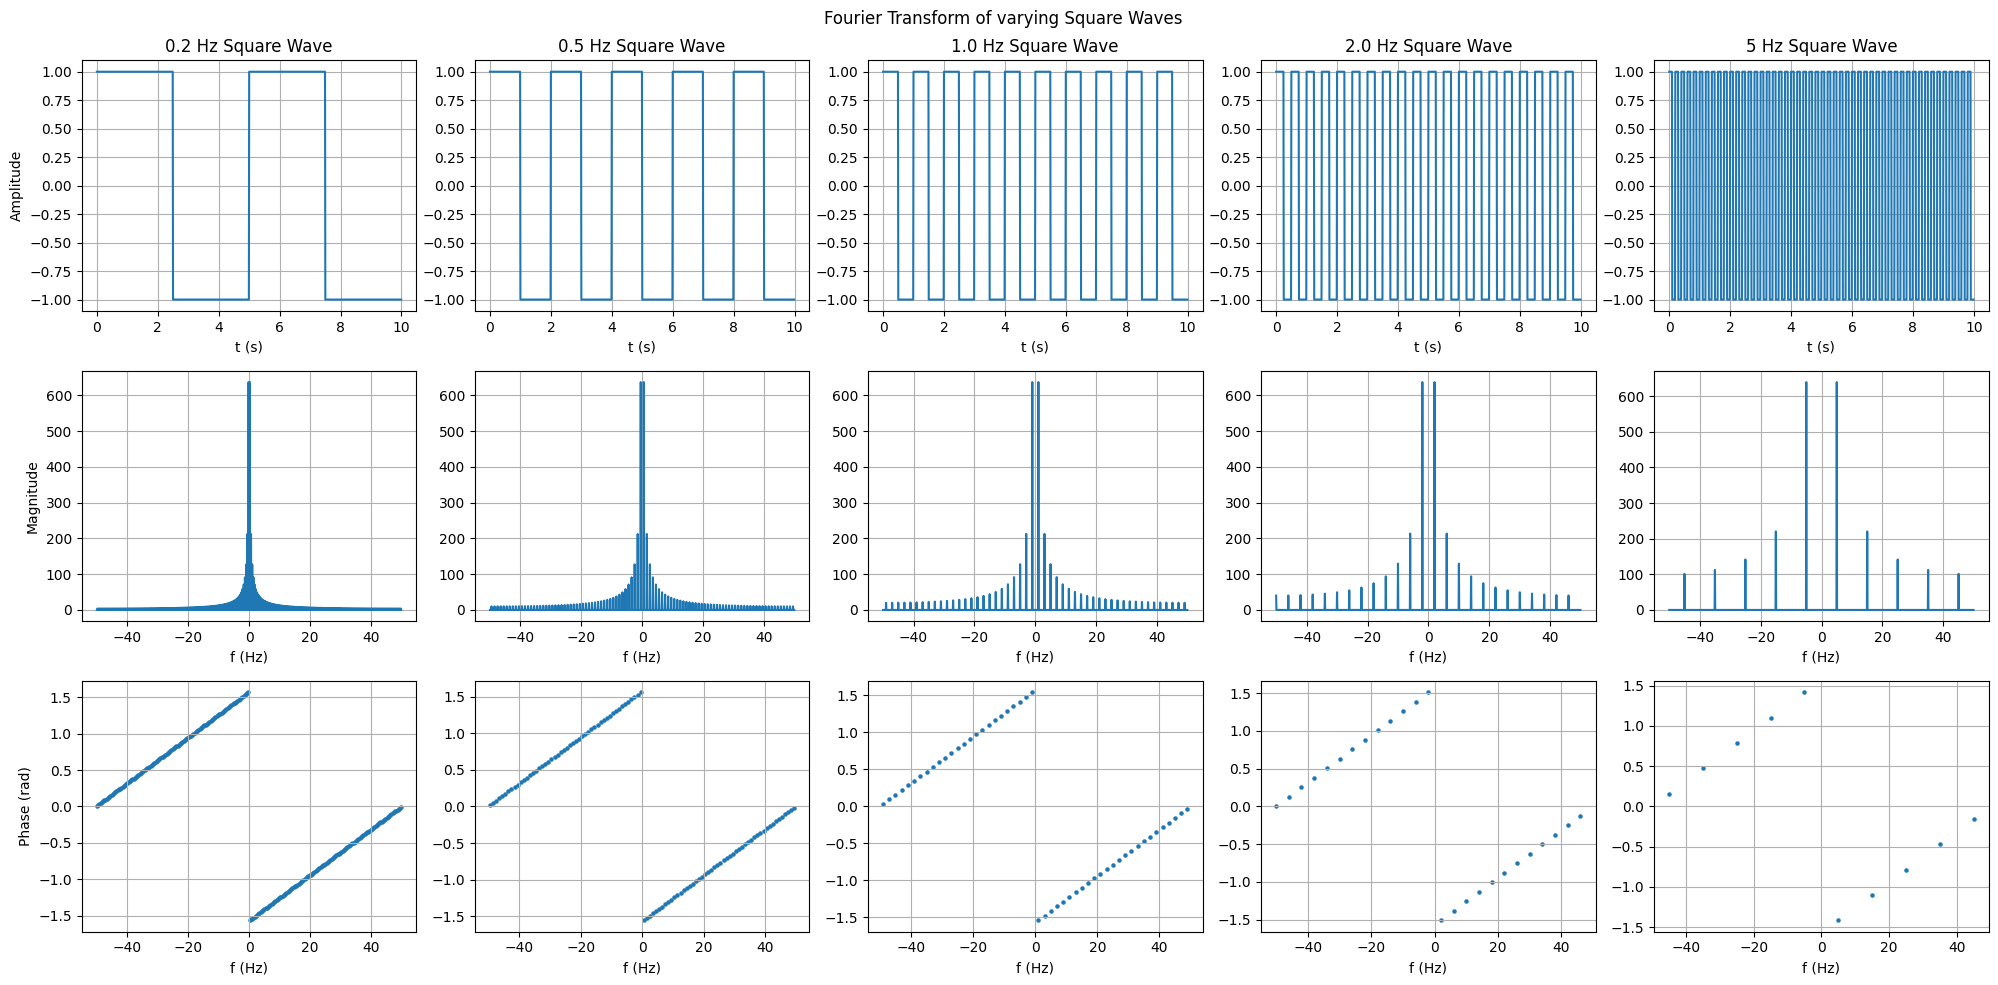

In [7]:
freq_axis = np.fft.fftshift(np.fft.fftfreq(N, interval))

fig, ax = plt.subplots(3, 5, figsize=(20,10))

for i, freq in enumerate(frequencies): 
    waveform = signal_data[freq]
    waveform_fft = np.fft.fftshift(np.fft.fft(waveform))
    mag = np.abs(waveform_fft)
    phase = np.angle(waveform_fft)
    threshold = mag > 1e-3 * mag.max()
    
    ax[0, i].plot(t, signal_data[freq])
    ax[0, i].set_title(f'{freq} Hz Square Wave')
    ax[0, i].set_xlabel('t (s)')
    ax[0, i].grid(True)

    ax[1, i].plot(freq_axis, mag)
    ax[1, i].set_xlabel('f (Hz)')
    ax[1, i].grid(True)

    ax[2, i].scatter(freq_axis[threshold], phase[threshold], s=5)
    ax[2, i].set_xlabel('f (Hz)')
    ax[2, i].grid(True)

ax[0, 0].set_ylabel('Amplitude')
ax[1, 0].set_ylabel('Magnitude')
ax[2, 0].set_ylabel('Phase (rad)')

plt.suptitle(f'Fourier Transform of varying Square Waves')
plt.savefig("square_freqs.png", dpi=600)
plt.tight_layout()
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [8]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 25000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]

signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

(0.0, 0.3)

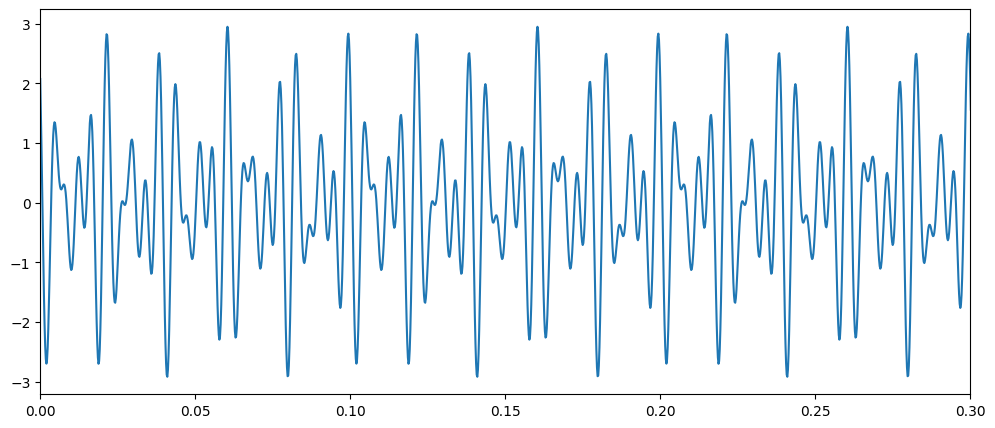

In [9]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0,0.3)

In [10]:
#FILL: Plot the fourier transform of the clean, original signal

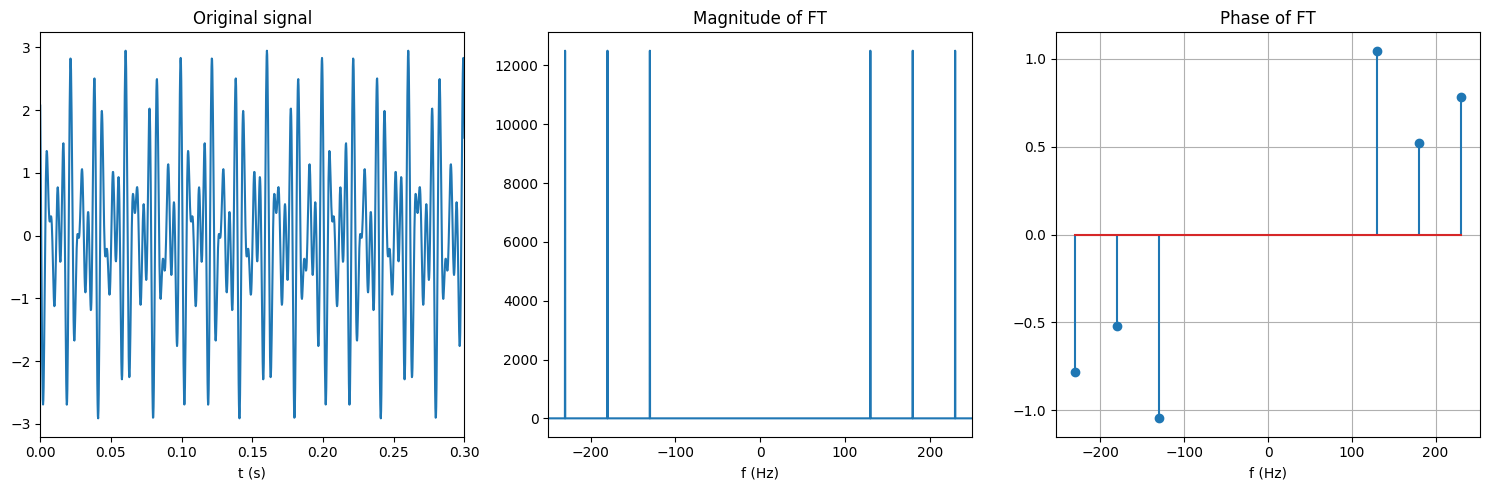

In [11]:
freq_axis = np.fft.fftshift(np.fft.fftfreq(N, dt))

signal_fft = np.fft.fftshift(np.fft.fft(signal_original))
mag = np.abs(signal_fft)
phase = np.angle(signal_fft)
threshold = mag > 1e-3 * mag.max()

fig, ax = plt.subplots(1, 3, figsize=(15,5))

ax[0].plot(t_, signal_original)
ax[0].set_title(f'Original signal')
ax[0].set_xlabel('t (s)')
ax[0].set_xlim(0,0.30)
#ax[0].grid(True)

ax[1].plot(freq_axis, mag)
ax[1].set_title(f'Magnitude of FT')
ax[1].set_xlabel('f (Hz)')
ax[1].set_xlim(-250,250)
#ax[1].grid(True)

ax[2].stem(freq_axis[threshold], phase[threshold])
ax[2].set_title(f'Phase of FT')
ax[2].set_xlabel('f (Hz)')
#ax[2].grid(True)

plt.grid(True)
plt.tight_layout()
plt.show()

In [12]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

(0.0, 0.3)

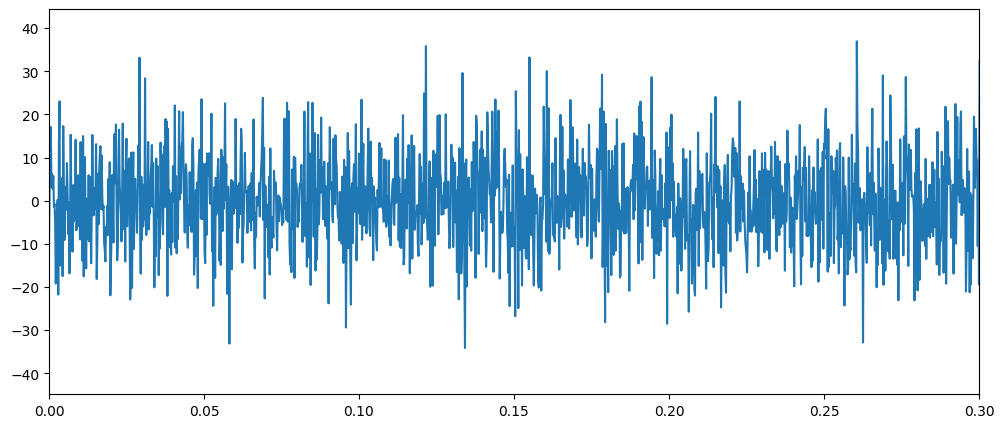

In [13]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.3)

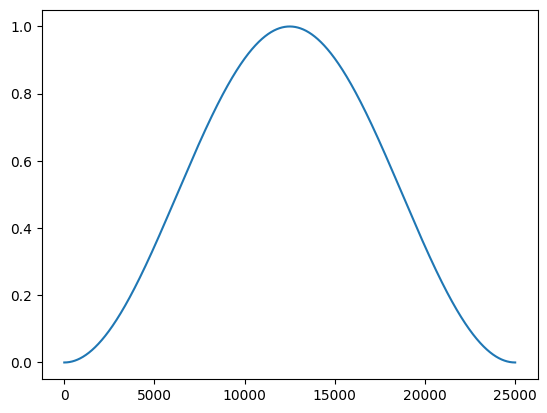

In [14]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)

In [15]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

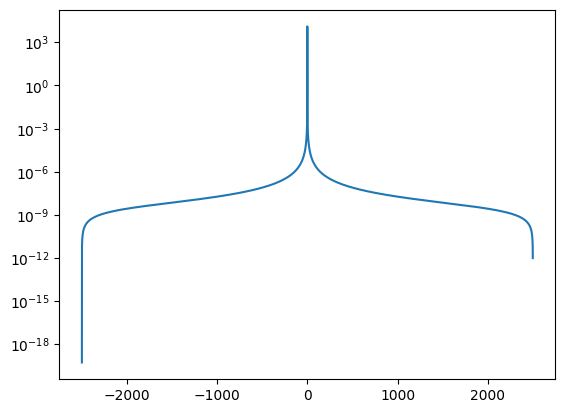

In [16]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

In [17]:
noisyFourier = np.fft.fft(noisy_data*window)
noisy_mag = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))
noisy_freq = np.fft.fftshift(np.fft.fftfreq(N, dt))

- Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window

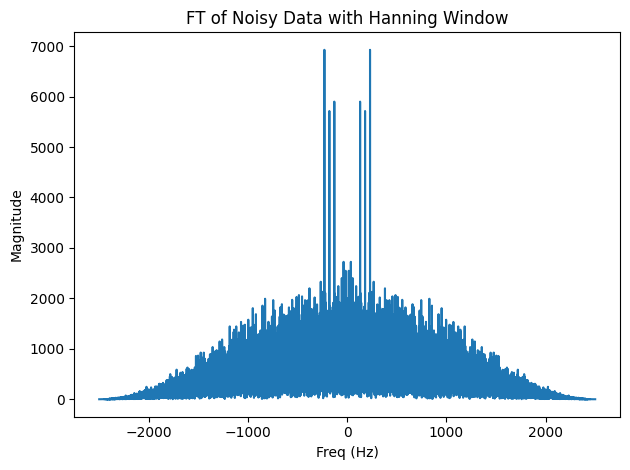

In [18]:
plt.plot(freq_axis, noisy_mag * window)
plt.title('FT of Noisy Data with Hanning Window')
plt.xlabel('Freq (Hz)')
plt.ylabel('Magnitude')
plt.tight_layout()
plt.show()

- Fill: Find a suitable threshold value to filter the noise in fourier space

In [19]:
threshold = 0.6 * np.max(np.abs(noisyFourier)) # about 0.6 keeps the signals while removing noise
filtered_signal = np.where(np.abs(noisyFourier) > threshold, noisyFourier, 0)

- Fill: with the cleaned signal in fourier space, convert it back to the time domain

In [20]:
recoveredSignal = np.real(np.fft.ifft(filtered_signal)) / 0.6 # we divide by 0.6 to recover what was lost when we adjusted for the threshold

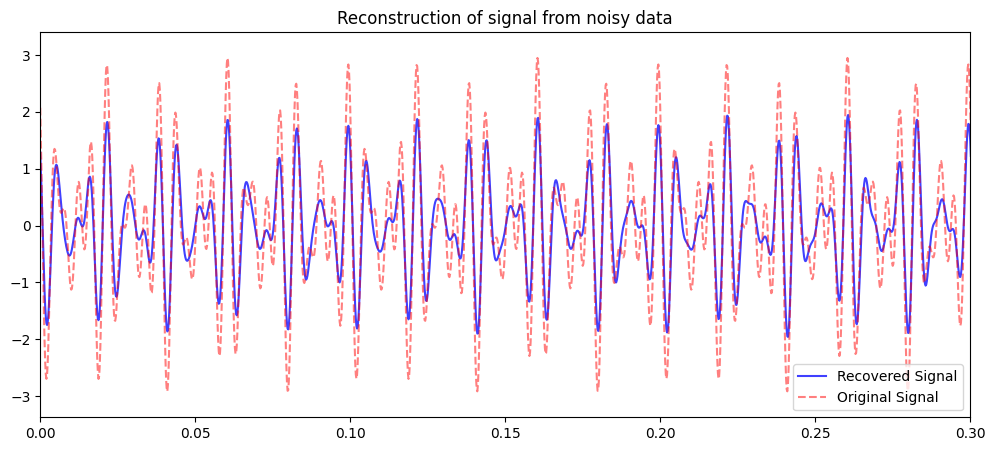

In [21]:
# Plot the recovered signal
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, recoveredSignal, color='blue', alpha=0.75, label='Recovered Signal')
ax.plot(t_, signal_original, color='red', ls='--', alpha=0.5, label='Original Signal')
ax.set_xlim(0,0.3)
ax.legend()
plt.title('Reconstruction of signal from noisy data')
plt.savefig("recover.png", dpi=600)
plt.show()

Let us now try recreating this but with a lower sample size

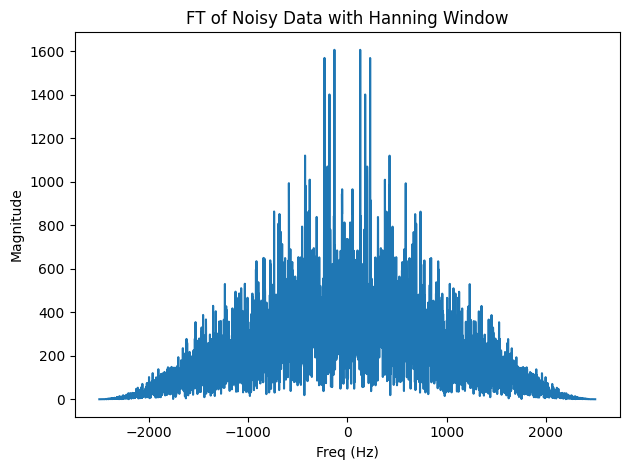

In [22]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 5000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]

signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

freq_axis = np.fft.fftshift(np.fft.fftfreq(N, dt))
noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

window = np.hanning(len(noisy_data))
noisyFourier = np.fft.fft(noisy_data*window)
noisy_mag = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))
noisy_freq = np.fft.fftshift(np.fft.fftfreq(N, dt))

plt.plot(freq_axis, noisy_mag * window)
plt.title('FT of Noisy Data with Hanning Window')
plt.xlabel('Freq (Hz)')
plt.ylabel('Magnitude')
plt.tight_layout()
plt.show()

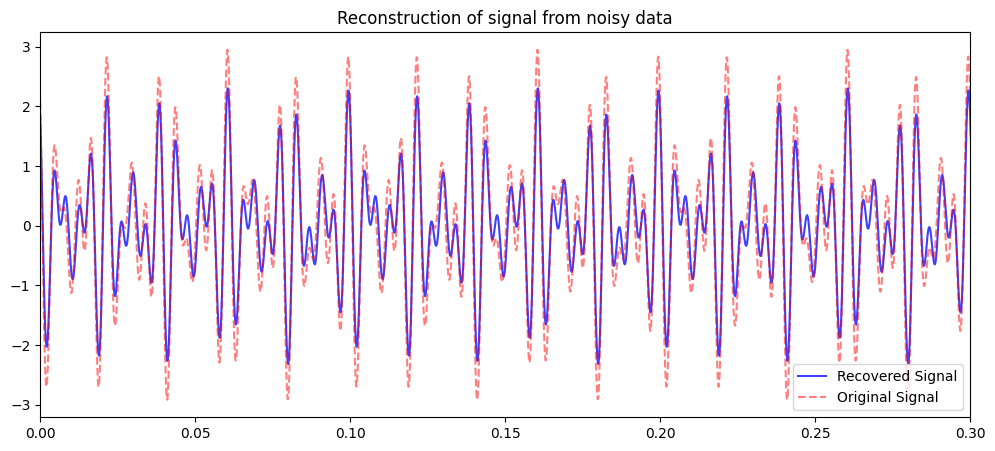

In [23]:
threshold = 0.8 * np.max(np.abs(noisyFourier)) # about 0.6 keeps the signals while removing noise
filtered_signal = np.where(np.abs(noisyFourier) > threshold, noisyFourier, 0)

recoveredSignal = np.real(np.fft.ifft(filtered_signal)) / 0.8 # we divide by 0.6 to recover what was lost when we adjusted for the threshold

# Plot the recovered signal
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, recoveredSignal, color='blue', alpha=0.75, label='Recovered Signal')
ax.plot(t_, signal_original, color='red', ls='--', alpha=0.5, label='Original Signal')
ax.set_xlim(0,0.3)
ax.legend()
plt.title('Reconstruction of signal from noisy data')
plt.savefig("recover_lowersample.png", dpi=600)
plt.show()

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
2) Get their fourier transforms. Are they the same?
3) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

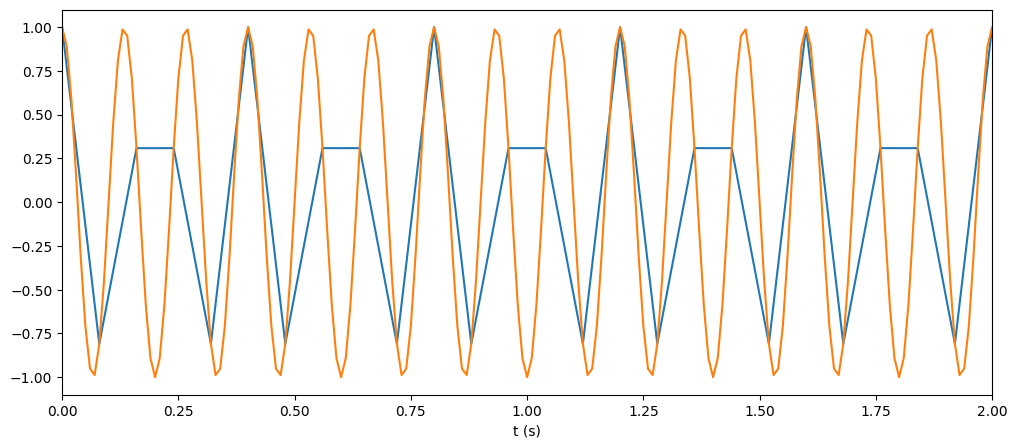

In [24]:
T = 10 # duration
n_sample = 125 # below nyquist rate for 12.5 Hz (aliased)
n_unaliased = 1000 # above nyquist rate (not aliased)
dt = T / n_sample
dt_u = T / n_unaliased
t_sample = np.arange(n_sample) * dt
t_unaliased = np.arange(n_unaliased) * dt_u

cont_signal = lambda t, freq: np.cos(2*np.pi*freq*t)

freq = 7.5
fs_a, fs_u = 1/dt, 1/dt_u
f_alias = abs(freq - fs_a * round(freq / fs_a)) 

discrete_signal = cont_signal(t_sample, freq)
discrete_unaliased = cont_signal(t_unaliased, freq)

fig, ax = plt.subplots(figsize=(12,5))

ax.plot(t_sample, discrete_signal)
ax.plot(t_unaliased, discrete_unaliased)
ax.set_xlim(0,2)
ax.set_xlabel('t (s)')
plt.show()

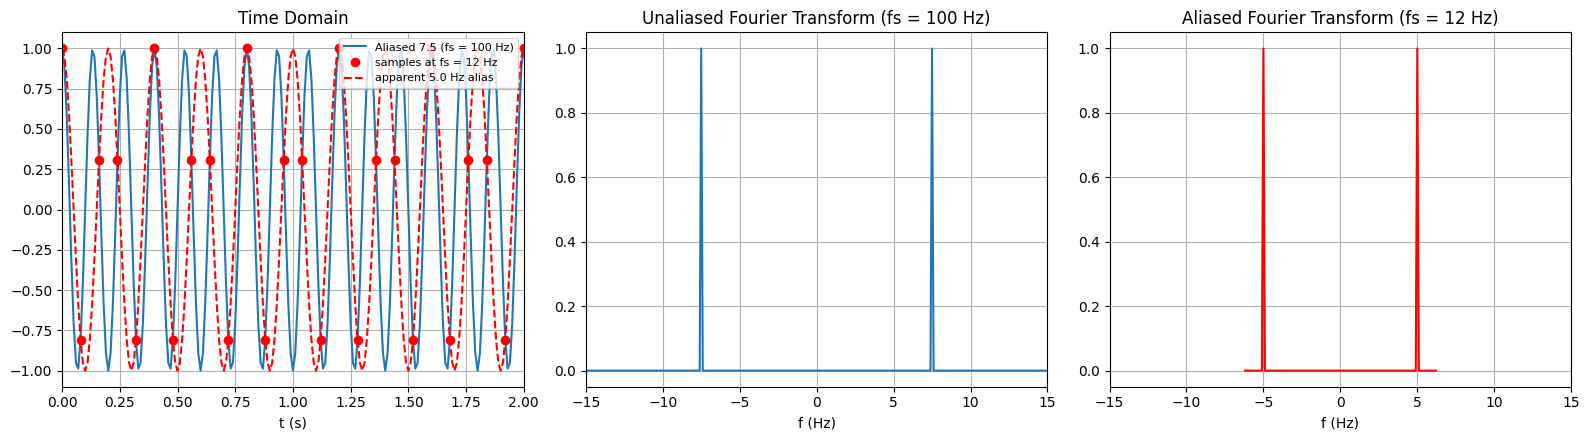

In [25]:
def spectrum(x, dt):
    X = np.fft.fftshift(np.fft.fft(x))
    f = np.fft.fftshift(np.fft.fftfreq(len(x), dt))
    return f, 2 * np.abs(X) / len(x) # normalized so a cosine of amplitude 1 peaks at 1

f_a, mag_a = spectrum(discrete_signal, dt)
f_u, mag_u = spectrum(discrete_unaliased, dt_u)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

ax[0].plot(t_unaliased, discrete_unaliased, label=f'Aliased {freq} (fs = {fs_u:.0f} Hz)')
ax[0].plot(t_sample, discrete_signal, 'o', color='red', label=f'samples at fs = {fs_a:.0f} Hz')
ax[0].plot(t_unaliased, cont_signal(t_unaliased, f_alias), '--', color='red', label=f'apparent {f_alias} Hz alias')
ax[0].set_xlim(0, 2)
ax[0].set_title('Time Domain')
ax[0].set_xlabel('t (s)')
ax[0].legend(loc='upper right', fontsize=8)
ax[0].grid(True)

ax[1].plot(f_u, mag_u)
ax[1].set_title(f'Unaliased Fourier Transform (fs = {fs_u:.0f} Hz)')
ax[1].set_xlabel('f (Hz)')
ax[1].set_xlim(-15, 15)
ax[1].grid(True)

ax[2].plot(f_a, mag_a, color='red')
ax[2].set_title(f'Aliased Fourier Transform (fs = {fs_a:.0f} Hz)')
ax[2].set_xlabel('f (Hz)')
ax[2].set_xlim(-15, 15)
ax[2].grid(True)

plt.tight_layout()
plt.savefig('aliasing.png', dpi=600)
plt.show()

We can see that the magnitude of the Fourier Tranform for aliased and unaliased signals are different, with peaks at ($\pm 7.5$ Hz) for unaliased and ($\pm 5$ Hz) for the aliased signal.

#### Problem code summary
The code was built to analyze various signals and compute their Fourier Transform using the FFT algorithm. In order to recover specific frequencies or rebuild the original signal, a threshold was implemented for all to filter out noise while preserving prevalent signals.

---
## Section 3: Notes

In [26]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

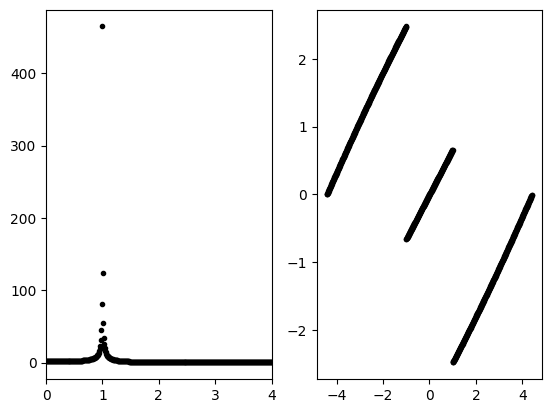

In [27]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [28]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

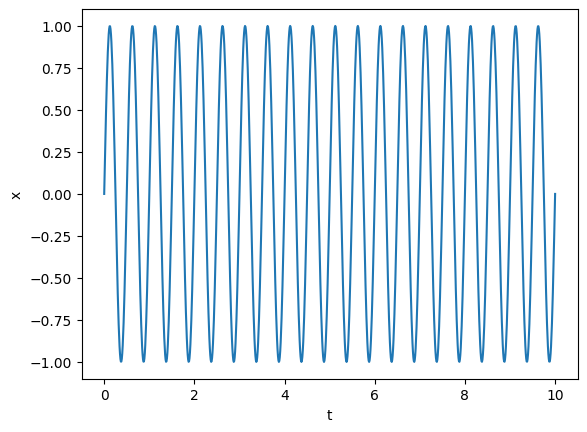

In [29]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [30]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0, device=None)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.
device : str, optional
    The device on which to place the created array. Default: ``None``.
    For Array-API interoperability only, so must be ``"cpu"`` if passed.

    .. versionadded:: 2.0.0

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> import numpy as np
>

### Plotting

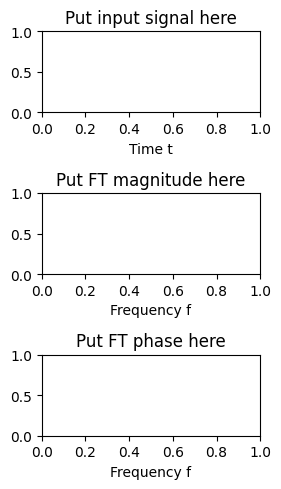

In [31]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

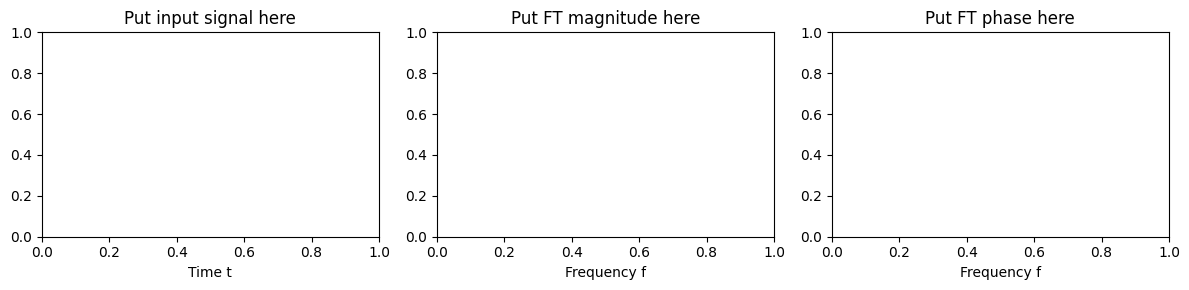

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

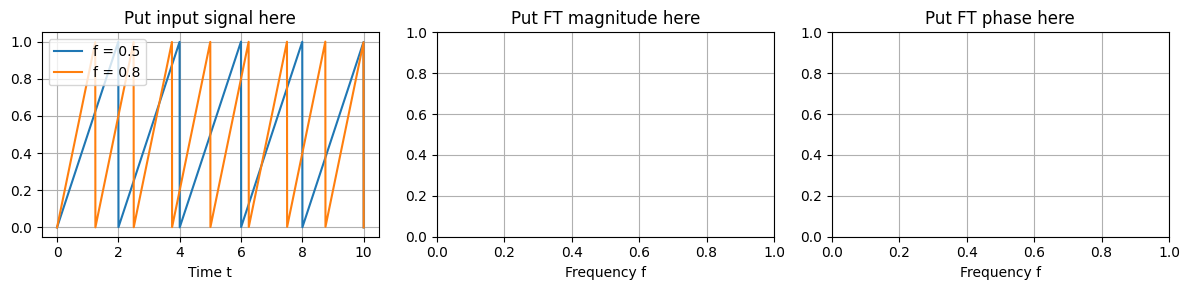

In [33]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [34]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



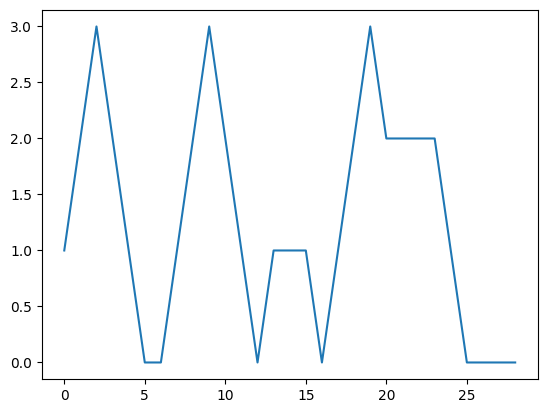

In [35]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [36]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [37]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

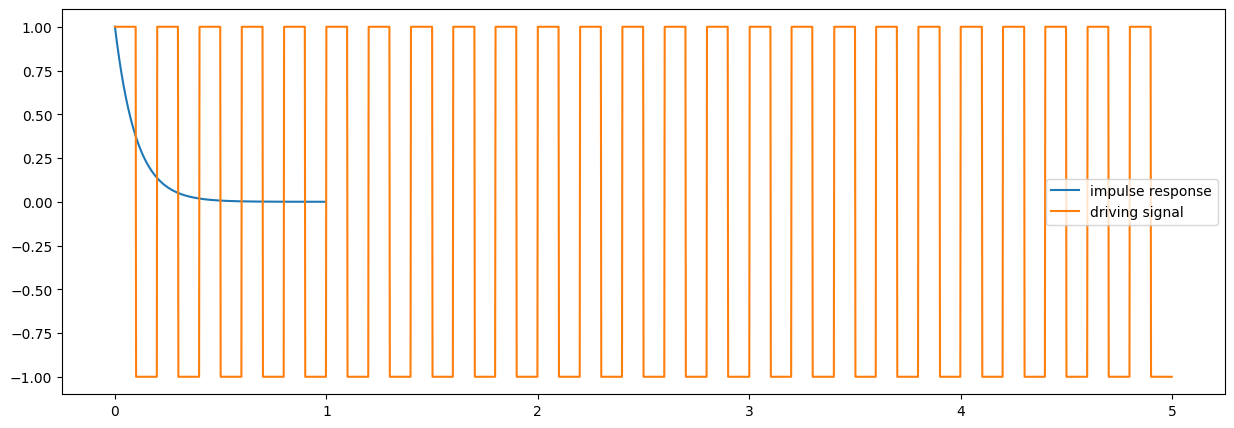

In [38]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [39]:
response = np.convolve(input_signal, h_t, mode = "same")

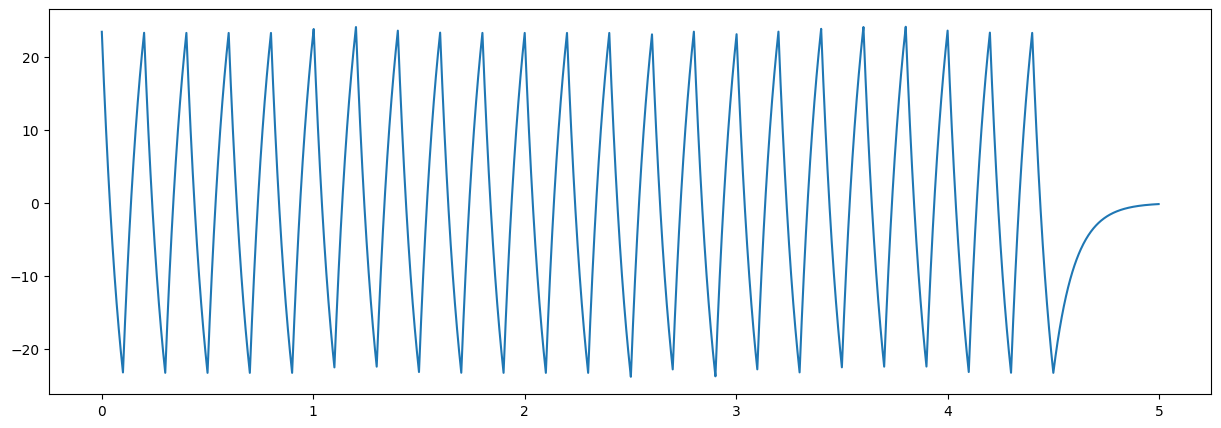

In [40]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [41]:
fourier_length = len(h_t) + len(input_signal) - 1

In [42]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [43]:
fourier_response = fourier_h*fourier_input 

In [44]:
response = np.real(np.fft.ifft(fourier_response))

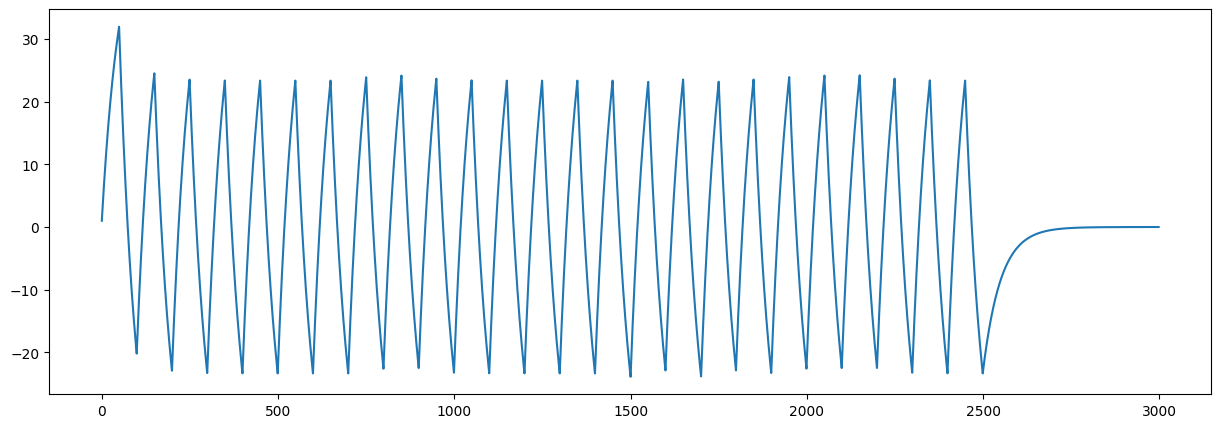

In [45]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)